# Disease Prediction from Medical Data
**Machine Learning-Based Health Risk Prediction System**

## 1. Project introduction
This notebook walks through the complete machine learning workflow for three prediction tasks:

`Medical dataset -> Data cleaning -> EDA -> Feature engineering -> Model training -> Model comparison -> Best model -> Prediction -> Web dashboard`

| Disease | Dataset | Target (1 = positive) |
|---|---|---|
| Heart Disease | UCI Heart Disease (Cleveland) | heart disease present |
| Diabetes | Pima Indians Diabetes | tested positive for diabetes |
| Breast Cancer | UCI Breast Cancer Wisconsin (Diagnostic) | malignant tumour |

> **Disclaimer:** this project is for educational purposes only. Predictions are statistical estimates, not medical diagnoses, and must not replace advice from a qualified healthcare professional.

All reusable logic lives in `src/` (config, data loading, preprocessing, EDA, training, prediction); the notebook calls it step by step so every stage can be inspected. Run the cells from top to bottom. Every number shown comes from actual computation - nothing is hard-coded.

## 2. Import libraries

In [1]:
import sys, warnings
from pathlib import Path

# make the project root importable whether the notebook runs from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.config import DISEASES, TARGET, RANDOM_STATE, MODELS_DIR, REPORTS_DIR, FIGURES_DIR
from src import data_loader, preprocessing, eda, train, plots, predict

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
print("Project root:", ROOT)

Project root: c:\Users\Pritish Manna\Downloads\Disease-Prediction\Disease-Prediction


## 3. Load datasets
Breast cancer is bundled with scikit-learn. Heart disease and diabetes are downloaded once from public sources and cached in `data/`. If you are offline, place `heart.csv` and `diabetes.csv` in `data/` manually (column names are listed in the README).

In [2]:
data_loader.ensure_all_datasets()
raw = {key: data_loader.load_dataset(key) for key in DISEASES}
for key, df in raw.items():
    print(DISEASES[key].title, df.shape)
    display(df.head(3))

Heart Disease (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1


Diabetes (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,target
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1


Breast Cancer (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1


## 4. Understand the datasets
For each dataset we check the shape, column names, data types and basic statistics. The target column is `target` (1 = disease present / positive class).

In [3]:
for key, df in raw.items():
    print("=" * 70)
    print(DISEASES[key].title, "| source:", DISEASES[key].source)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    display(df.dtypes.to_frame("dtype").T)
    display(df.describe().T.round(2))

Heart Disease | source: UCI Machine Learning Repository - Heart Disease (Cleveland database)
Shape: (303, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


Diabetes | source: Pima Indians Diabetes Database (National Institute of Diabetes and Digestive and Kidney Diseases), available via UCI / OpenML
Shape: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'target']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,target
dtype,int64,int64,int64,int64,int64,float64,float64,int64,int64


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
target,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


Breast Cancer | source: UCI Machine Learning Repository - Breast Cancer Wisconsin (Diagnostic), bundled with scikit-learn
Shape: (569, 31)
Columns: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
mean concavity,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
mean concave points,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
mean symmetry,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
mean fractal dimension,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


## 5. Data cleaning
`clean_dataset` performs only *stateless* cleaning, so it is safe to do before the train/test split:

* keep the expected columns and convert them to numbers,
* mark physiologically impossible zeros as missing (diabetes: Glucose, BloodPressure, SkinThickness, Insulin, BMI),
* mark values outside plausible ranges as missing,
* drop rows without a target and remove duplicate records.

Anything that learns from data (median values, scaling, encoding) is deliberately left for the pipeline, which is fitted on the training split only.

In [4]:
clean, logs = {}, {}
for key, cfg in DISEASES.items():
    clean[key], logs[key] = preprocessing.clean_dataset(cfg, raw[key])
    print(cfg.title)
    for name, value in logs[key].items():
        print(f"  {name}: {value}")

Heart Disease
  rows_raw: 303
  zero_marked_missing: {}
  out_of_range_marked_missing: {}
  rows_without_target_dropped: 0
  duplicates_removed: 0
  rows_clean: 303
  missing_after_cleaning: {'ca': 4, 'thal': 2}
Diabetes
  rows_raw: 768
  zero_marked_missing: {'Glucose': 5, 'BloodPressure': 35, 'SkinThickness': 227, 'Insulin': 374, 'BMI': 11}
  out_of_range_marked_missing: {}
  rows_without_target_dropped: 0
  duplicates_removed: 0
  rows_clean: 768
  missing_after_cleaning: {'Glucose': 5, 'BloodPressure': 35, 'SkinThickness': 227, 'Insulin': 374, 'BMI': 11}
Breast Cancer
  rows_raw: 569
  zero_marked_missing: {}
  out_of_range_marked_missing: {}
  rows_without_target_dropped: 0
  duplicates_removed: 0
  rows_clean: 569
  missing_after_cleaning: {}


## 6. Missing-value analysis
The charts count real missing values plus impossible zeros in the raw data. These gaps are filled later by a median (numeric) or most-frequent (categorical) imputer fitted on the training data.

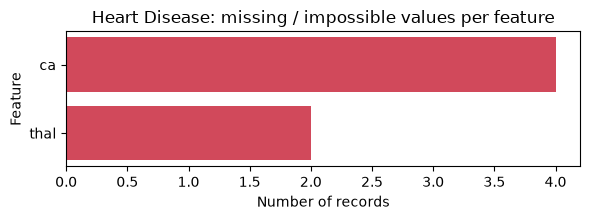

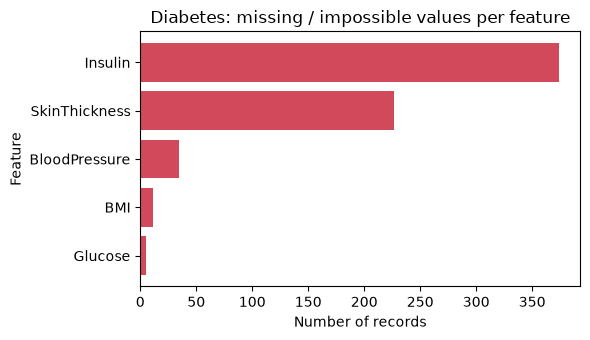

Breast Cancer: no missing or impossible values found.


In [5]:
for key, cfg in DISEASES.items():
    eda.plot_missing(raw[key], cfg, show=True)
    plt.show()

## 7. Exploratory Data Analysis
For every disease we look at the class distribution (and class imbalance), age distribution where available, histograms and box plots of the features most associated with the target, and a correlation heatmap. The interpretation notes printed under each set of charts are computed from the data.

###################################################################### 
 Heart Disease


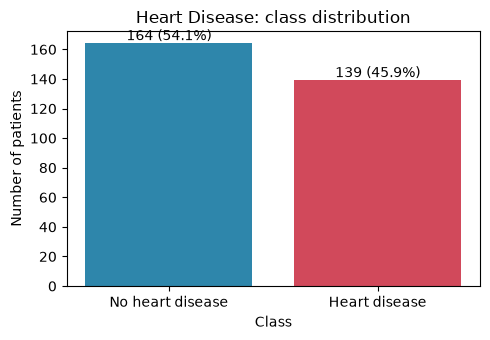

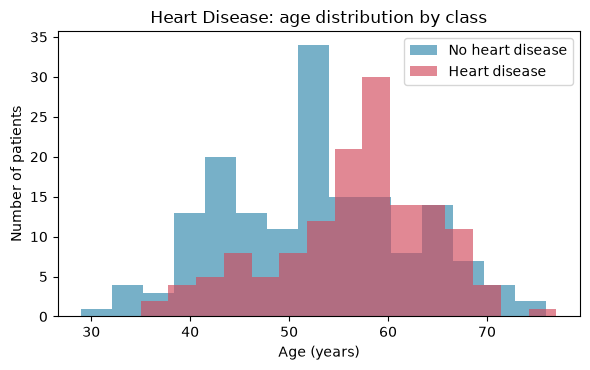

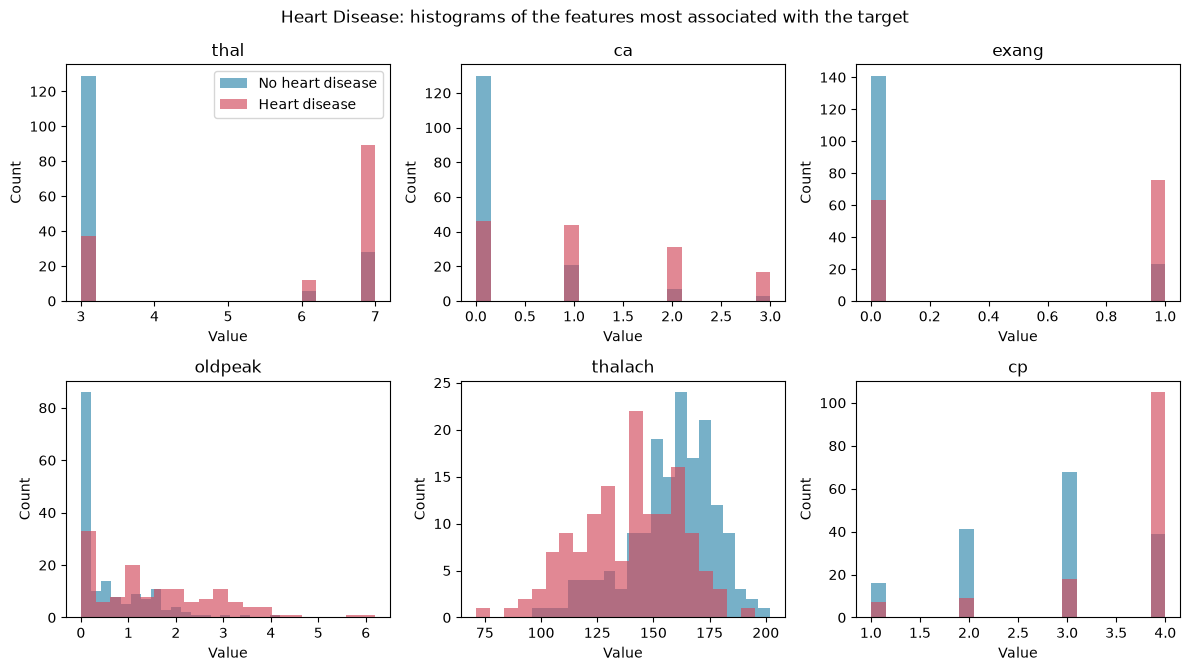

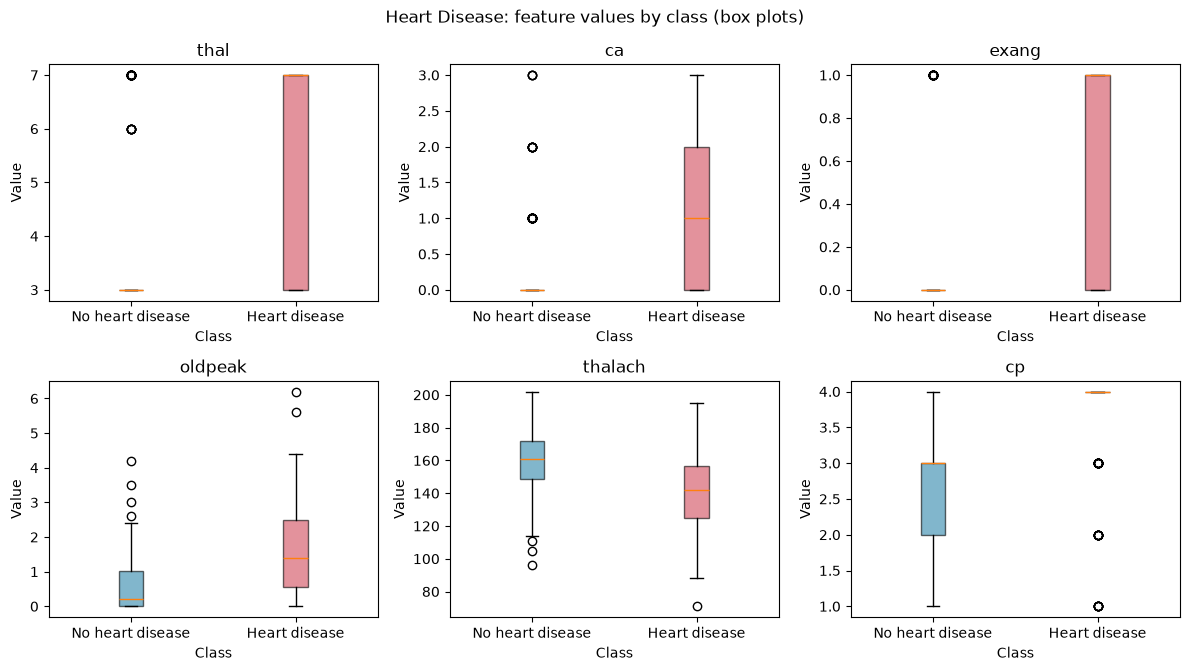

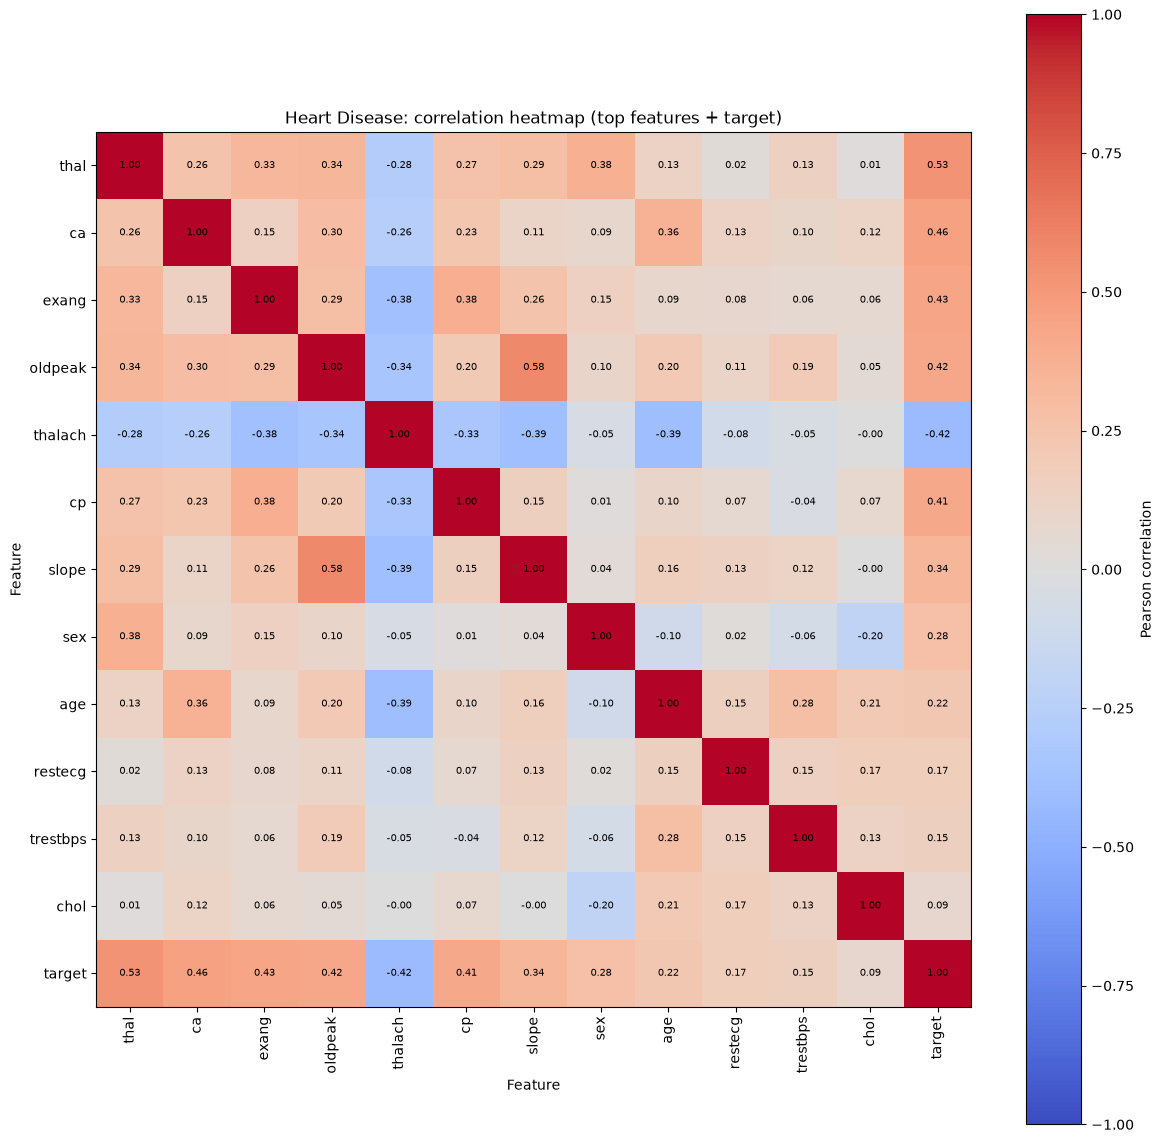

- Class balance: 139 of 303 records (45.9%) are 'Heart disease' and 164 are 'No heart disease' - the data is roughly balanced (ratio 1.18:1). Recall, F1 and ROC-AUC are reported alongside accuracy for this reason.
- Median age is 58.0 years for 'Heart disease' versus 52.0 years for 'No heart disease'.
- Features most correlated with the target: thal (r=+0.53), ca (r=+0.46), exang (r=+0.43), oldpeak (r=+0.42). Correlation describes association in this dataset, not cause and effect; categorical codes (e.g. chest pain type) are treated as numbers here, so their correlation is only approximate.
- Strongest correlation between two shown features: oldpeak and slope (r=+0.58). Highly correlated features carry overlapping information, which matters when reading coefficients or importances.
###################################################################### 
 Diabetes


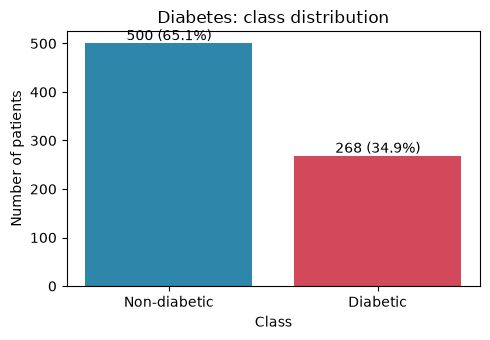

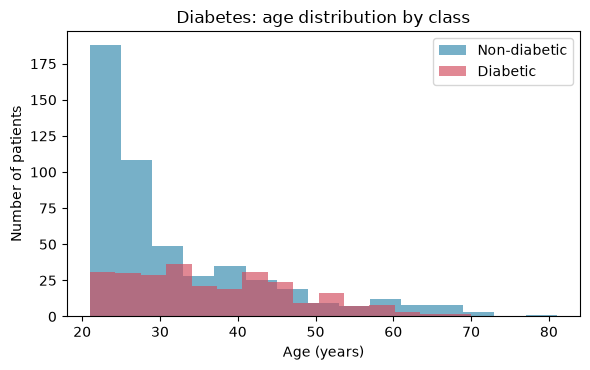

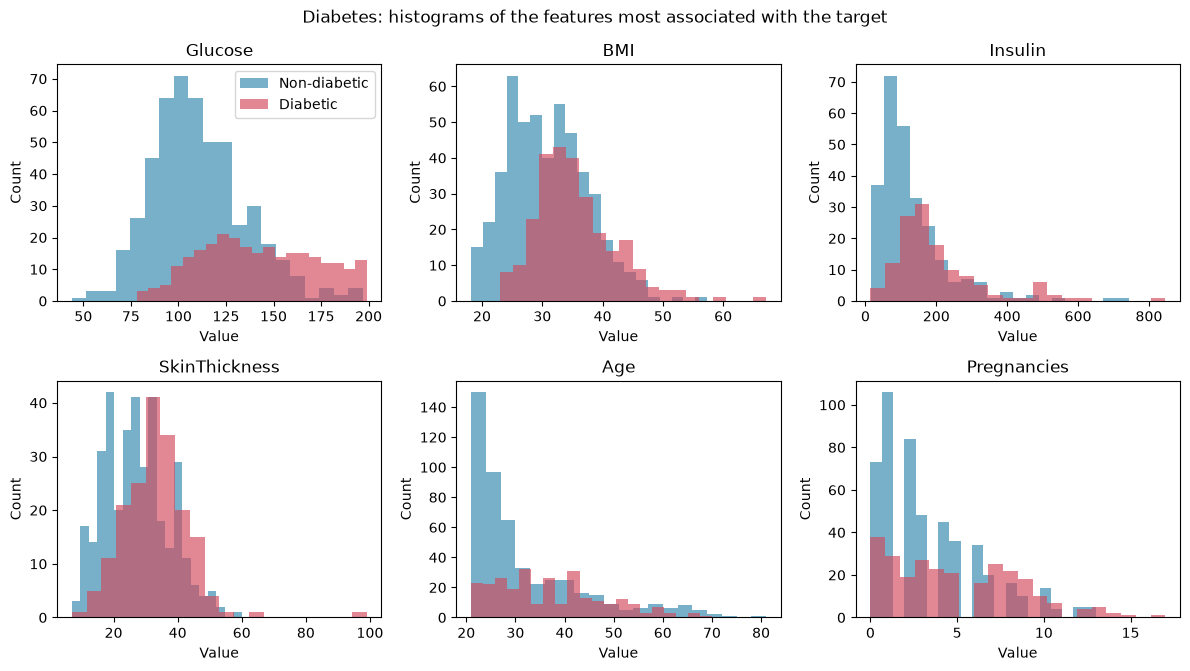

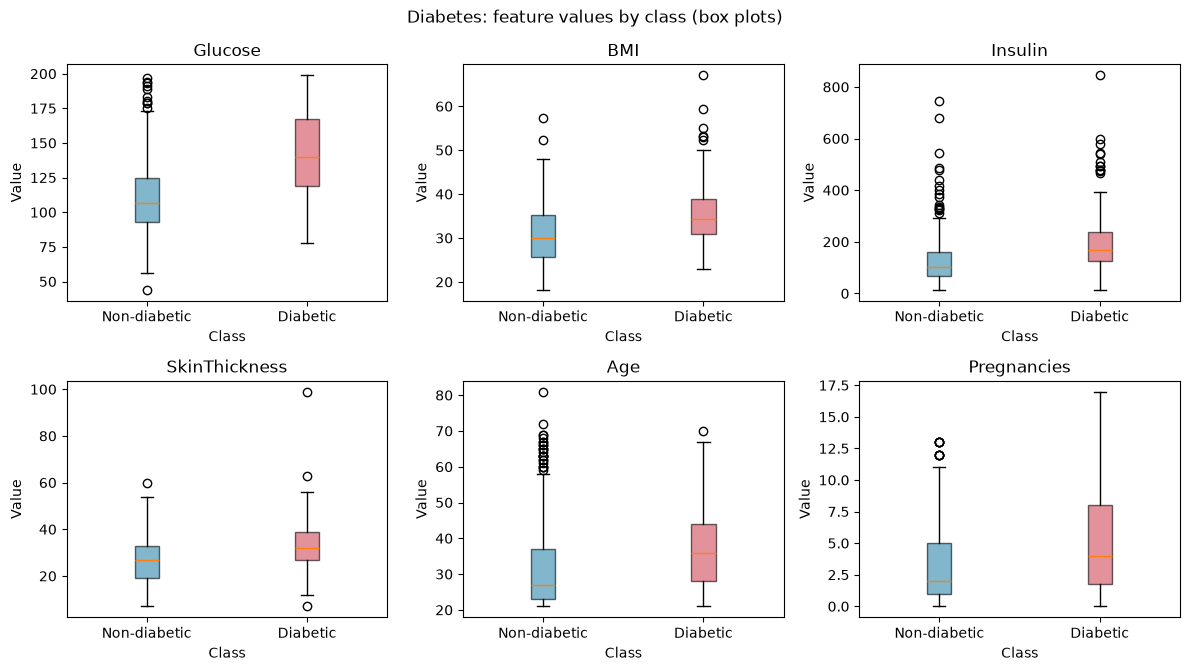

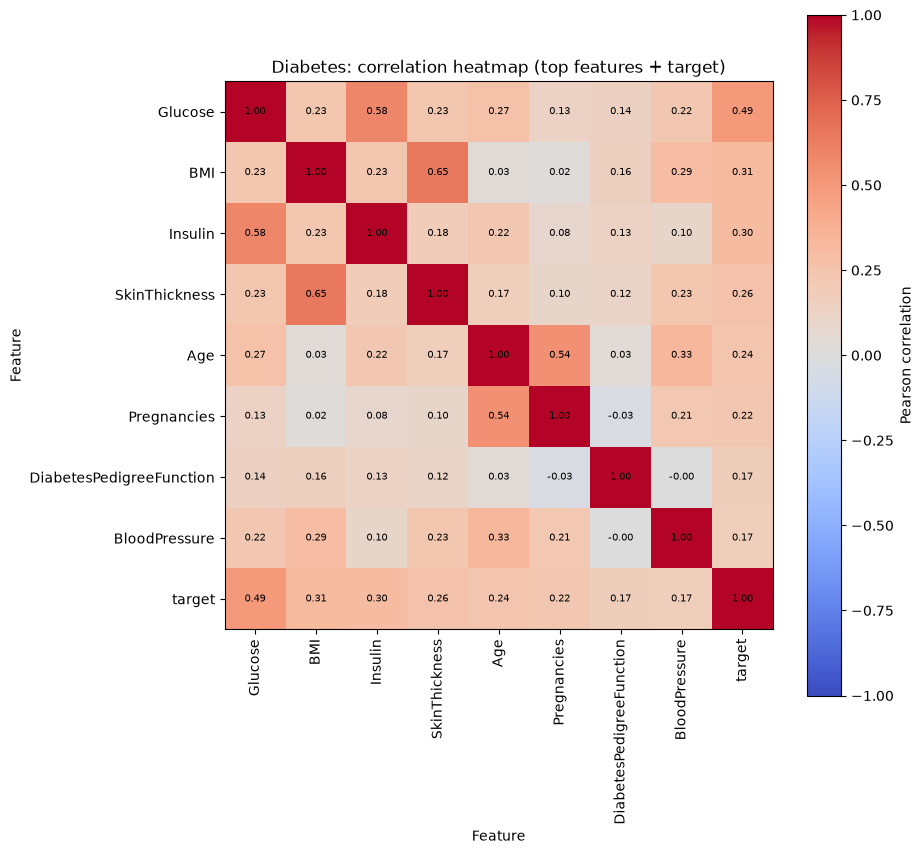

- Class balance: 268 of 768 records (34.9%) are 'Diabetic' and 500 are 'Non-diabetic' - the data is moderately imbalanced (ratio 1.87:1). Recall, F1 and ROC-AUC are reported alongside accuracy for this reason.
- Median age is 36.0 years for 'Diabetic' versus 27.0 years for 'Non-diabetic'.
- Features most correlated with the target: Glucose (r=+0.49), BMI (r=+0.31), Insulin (r=+0.30), SkinThickness (r=+0.26). Correlation describes association in this dataset, not cause and effect; categorical codes (e.g. chest pain type) are treated as numbers here, so their correlation is only approximate.
- Strongest correlation between two shown features: BMI and SkinThickness (r=+0.65). Highly correlated features carry overlapping information, which matters when reading coefficients or importances.
###################################################################### 
 Breast Cancer


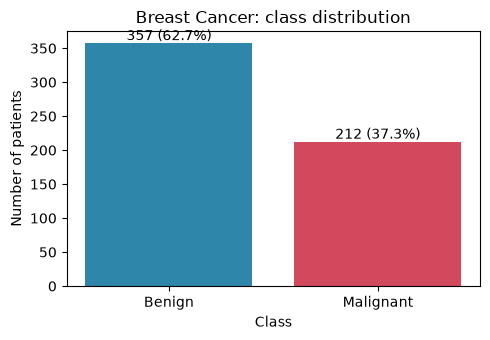

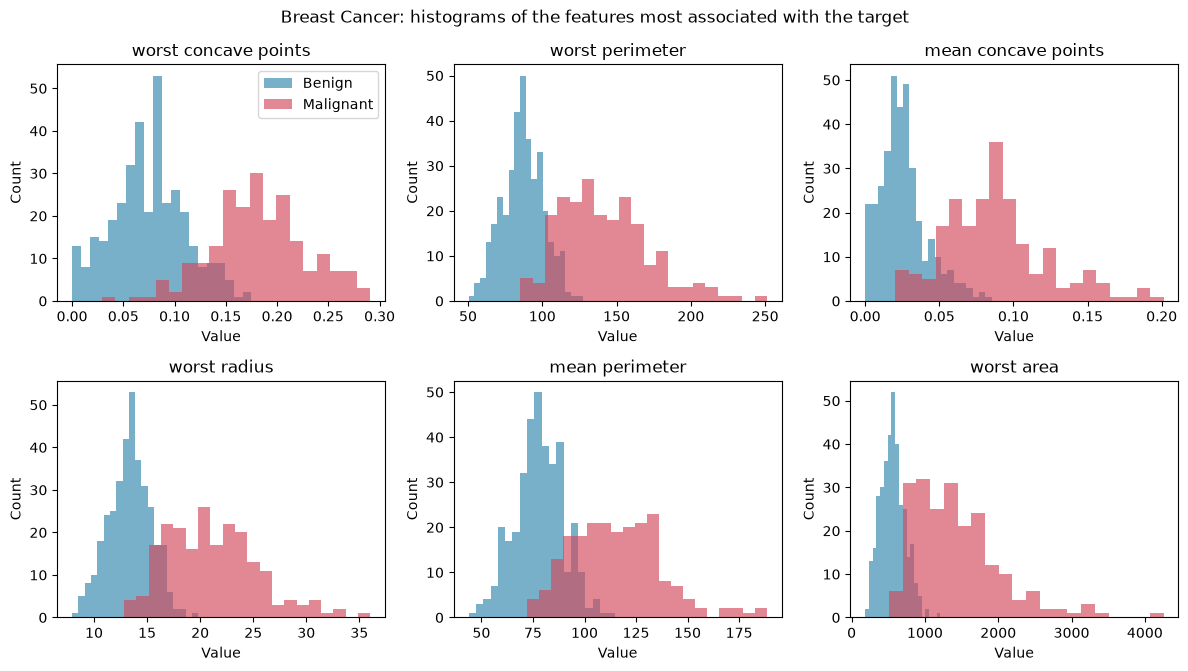

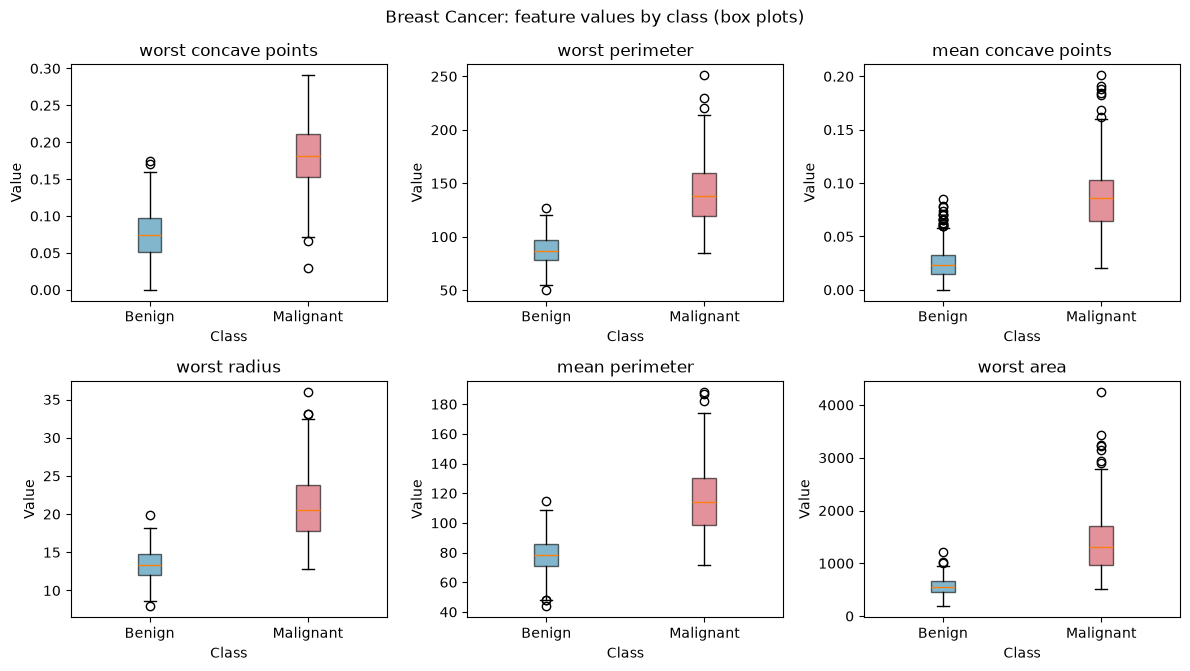

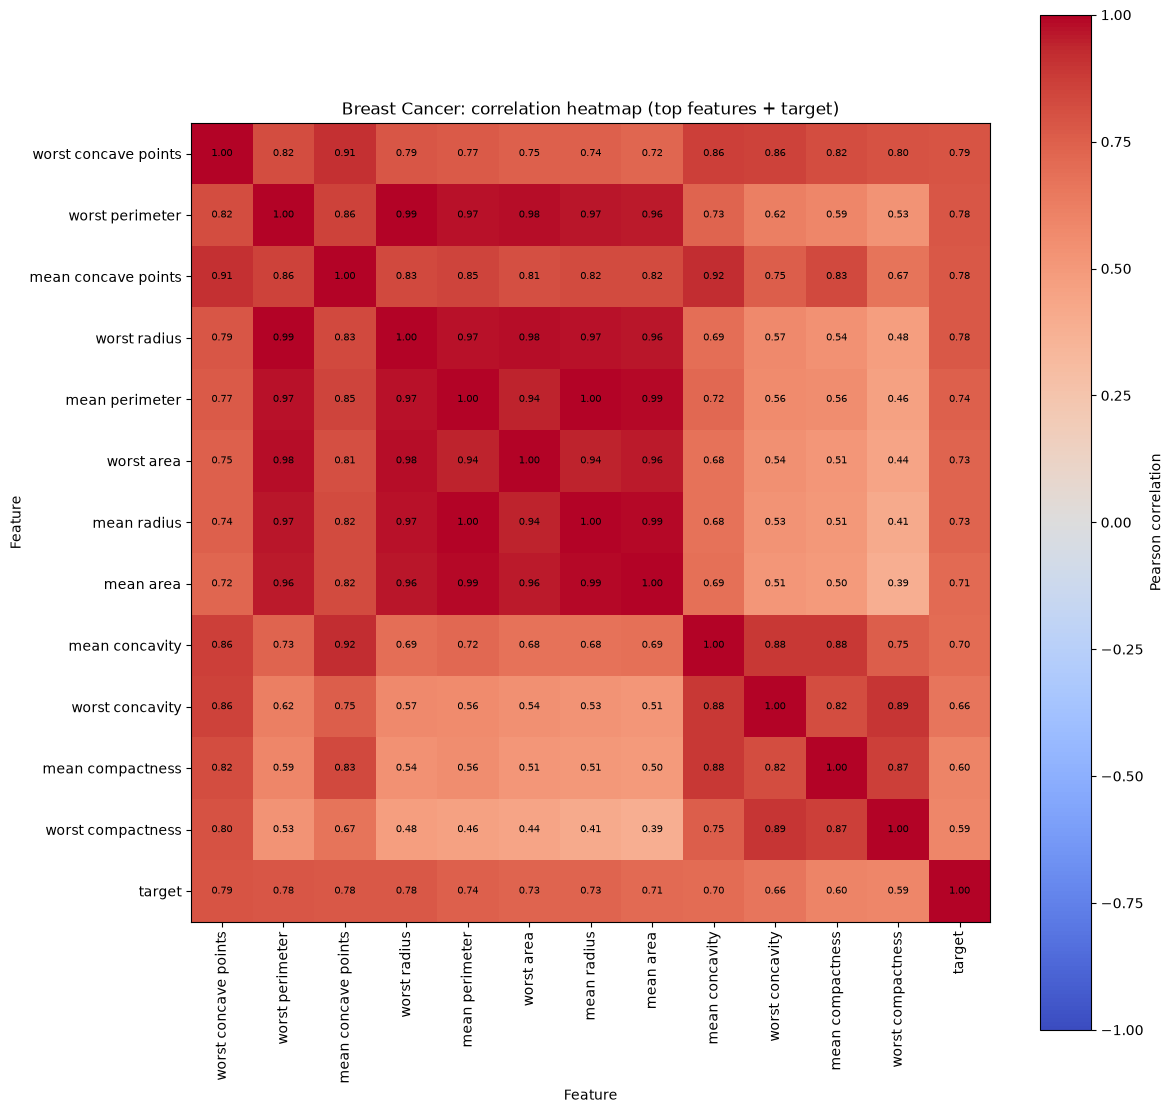

- Class balance: 212 of 569 records (37.3%) are 'Malignant' and 357 are 'Benign' - the data is moderately imbalanced (ratio 1.68:1). Recall, F1 and ROC-AUC are reported alongside accuracy for this reason.
- Features most correlated with the target: worst concave points (r=+0.79), worst perimeter (r=+0.78), mean concave points (r=+0.78), worst radius (r=+0.78). Correlation describes association in this dataset, not cause and effect; categorical codes (e.g. chest pain type) are treated as numbers here, so their correlation is only approximate.
- Strongest correlation between two shown features: mean perimeter and mean radius (r=+1.00). Highly correlated features carry overlapping information, which matters when reading coefficients or importances.


In [6]:
eda_notes = {}
for key, cfg in DISEASES.items():
    print("#" * 70, "\n", cfg.title)
    eda_notes[key] = eda.run_eda(cfg, clean[key], show=True, save=False)
    plt.show()
    for note in eda_notes[key]:
        print("-", note)

## 8. Feature engineering
The datasets already contain informative clinical measurements, so no artificial features are invented. Feature engineering here means preparing each column for modelling:

* **numeric features** - median imputation, then standardisation (needed for Logistic Regression and SVM, harmless for tree models);
* **categorical features** - most-frequent imputation, then one-hot encoding (e.g. chest pain type, thalassemia result);
* **binary flags** (sex, fasting blood sugar, exercise angina) - treated as 0/1 numeric values.

In [7]:
for key, cfg in DISEASES.items():
    print(f"{cfg.title}: {len(cfg.numeric_features)} numeric, {len(cfg.categorical_features)} categorical")
    print("  categorical (one-hot):", cfg.categorical_features or "none")

Heart Disease: 9 numeric, 4 categorical
  categorical (one-hot): ['cp', 'restecg', 'slope', 'thal']
Diabetes: 8 numeric, 0 categorical
  categorical (one-hot): none
Breast Cancer: 30 numeric, 0 categorical
  categorical (one-hot): none


## 9. Train/test split
An 80:20 **stratified** split keeps the class proportions the same in both sets. A fixed random seed makes the split reproducible. The test set is not used for any modelling decision.

In [8]:
splits = {}
for key, cfg in DISEASES.items():
    X_train, X_test, y_train, y_test = preprocessing.split_data(cfg, clean[key])
    splits[key] = (X_train, X_test, y_train, y_test)
    print(f"{cfg.title}: train {X_train.shape}, test {X_test.shape}, "
          f"positive rate train {y_train.mean():.3f} / test {y_test.mean():.3f}")

Heart Disease: train (242, 13), test (61, 13), positive rate train 0.459 / test 0.459
Diabetes: train (614, 8), test (154, 8), positive rate train 0.349 / test 0.351
Breast Cancer: train (455, 30), test (114, 30), positive rate train 0.374 / test 0.368


## 10. Preprocessing
The preprocessor is fitted on the **training data only** and then applied to the test data - this prevents data leakage. Inside the final models it is part of a scikit-learn `Pipeline`, so cross-validation refits it on every fold and the saved model contains it.

In [9]:
for key, cfg in DISEASES.items():
    X_train, X_test, _, _ = splits[key]
    pre = preprocessing.build_preprocessor(cfg)
    Xt = pre.fit_transform(X_train)
    Xv = pre.transform(X_test)
    print(f"{cfg.title}: {X_train.shape[1]} raw features -> {Xt.shape[1]} model inputs; "
          f"test matrix {Xv.shape}; NaN left after imputing: {int(np.isnan(Xt).sum())}")

Heart Disease: 13 raw features -> 22 model inputs; test matrix (61, 22); NaN left after imputing: 0
Diabetes: 8 raw features -> 8 model inputs; test matrix (154, 8); NaN left after imputing: 0
Breast Cancer: 30 raw features -> 30 model inputs; test matrix (114, 30); NaN left after imputing: 0


## 11-14. Training the four algorithms (baseline)
Each model is first trained with default settings (plus class weighting for imbalance) so we have a baseline. All four use the same preprocessing pipeline. Metrics are computed on the held-out test set from predicted probabilities with a 0.5 threshold.

* **Logistic Regression** - interpretable linear baseline.
* **SVM (RBF kernel)** - works on standardised features; probabilities enabled.
* **Random Forest** - tree ensemble, gives feature importance.
* **XGBoost** - gradient-boosted trees (requires the `xgboost` package).

In [10]:
baseline_pipes, baseline_res = {}, {}

def run_model(name):
    """Train one algorithm on every disease and show its test metrics."""
    rows = {}
    for key, cfg in DISEASES.items():
        X_train, X_test, y_train, y_test = splits[key]
        spw = (y_train == 0).sum() / (y_train == 1).sum()
        models = train.make_models(spw)
        if name not in models:
            print(f"{name} is not available: {train.XGBOOST_ERROR}")
            return None
        pipe = train.build_pipeline(cfg, models[name][0]).fit(X_train, y_train)
        baseline_pipes[(key, name)] = pipe
        baseline_res[(key, name)] = train.evaluate(pipe, X_test, y_test, cfg.class_names)
        rows[cfg.title] = baseline_res[(key, name)]["metrics"]
    table = pd.DataFrame(rows).T.round(3)
    display(table)
    return table

run_model("Logistic Regression");

,accuracy,precision,recall,f1,roc_auc
Heart Disease,0.869,0.812,0.929,0.867,0.958
Diabetes,0.734,0.603,0.704,0.650,0.813
Breast Cancer,0.974,0.976,0.952,0.964,0.995


In [11]:
run_model("SVM");

c:\Users\Pritish Manna\Downloads\Disease-Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Pritish Manna\Downloads\Disease-Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Pritish Manna\Downloads\Disease-Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,accuracy,precision,recall,f1,roc_auc
Heart Disease,0.902,0.844,0.964,0.900,0.956
Diabetes,0.747,0.660,0.574,0.614,0.814
Breast Cancer,0.982,0.976,0.976,0.976,0.995


In [12]:
run_model("Random Forest");

,accuracy,precision,recall,f1,roc_auc
Heart Disease,0.902,0.844,0.964,0.900,0.937
Diabetes,0.753,0.638,0.685,0.661,0.824
Breast Cancer,0.974,1.000,0.929,0.963,0.998


In [13]:
run_model("XGBoost");

,accuracy,precision,recall,f1,roc_auc
Heart Disease,0.869,0.812,0.929,0.867,0.927
Diabetes,0.753,0.660,0.611,0.635,0.817
Breast Cancer,0.982,1.000,0.952,0.976,0.991


## 15. Model evaluation
Beyond accuracy we look at **precision** (how many flagged cases are real), **recall/sensitivity** (how many real cases are caught), **F1**, **ROC-AUC** (ranking quality across thresholds) and the **confusion matrix**. In a medical setting a missed case (false negative) is usually more costly than a false alarm, so recall deserves extra attention - especially with class imbalance, where accuracy alone can be misleading.

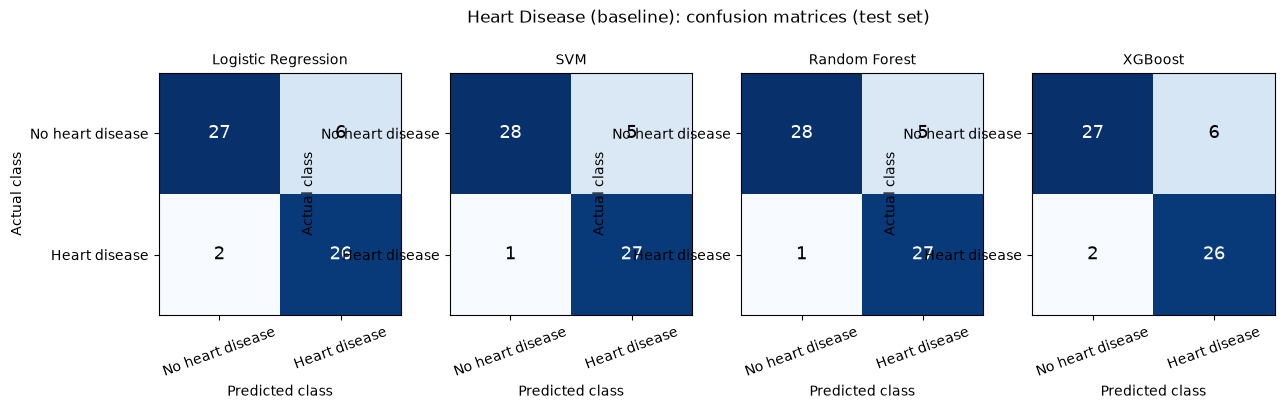

Classification report - Heart Disease, SVM (highest baseline F1):
                  precision    recall  f1-score   support

No heart disease       0.97      0.85      0.90        33
   Heart disease       0.84      0.96      0.90        28

        accuracy                           0.90        61
       macro avg       0.90      0.91      0.90        61
    weighted avg       0.91      0.90      0.90        61



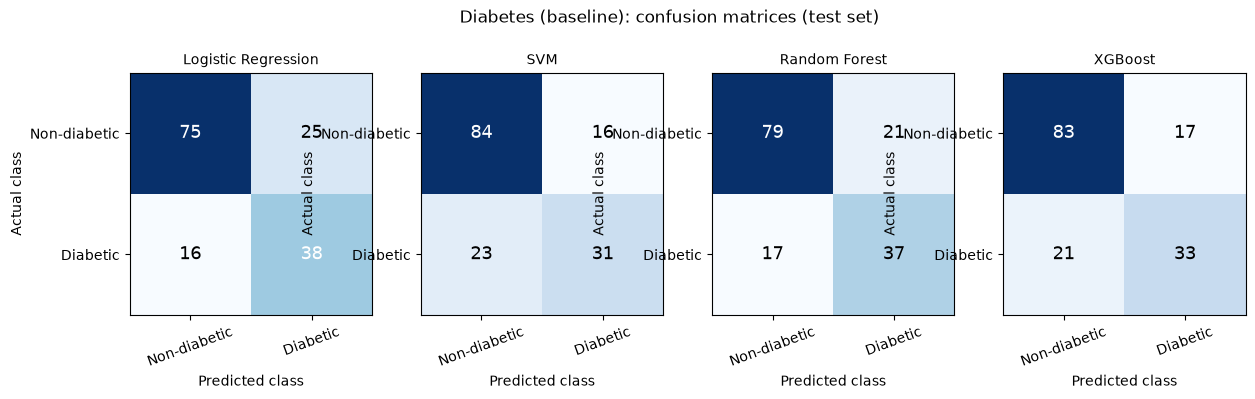

Classification report - Diabetes, Random Forest (highest baseline F1):
              precision    recall  f1-score   support

Non-diabetic       0.82      0.79      0.81       100
    Diabetic       0.64      0.69      0.66        54

    accuracy                           0.75       154
   macro avg       0.73      0.74      0.73       154
weighted avg       0.76      0.75      0.76       154



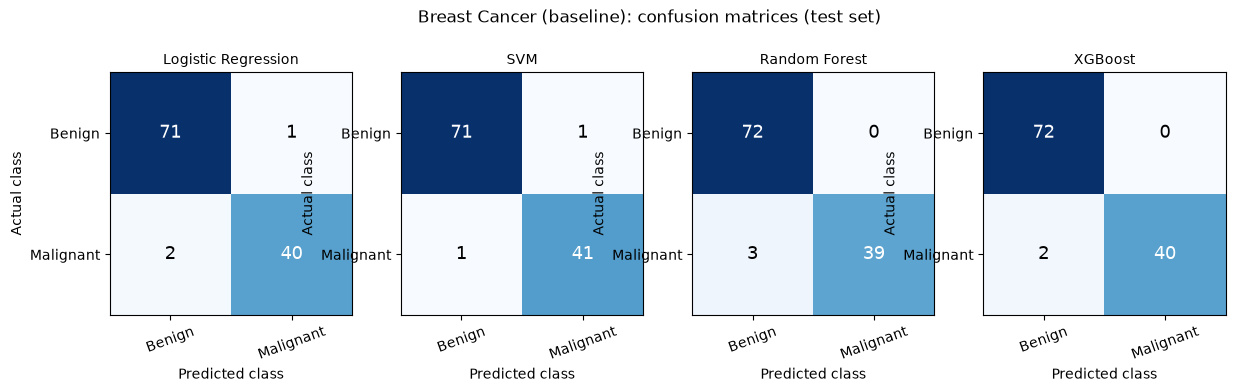

Classification report - Breast Cancer, SVM (highest baseline F1):
              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99        72
   Malignant       0.98      0.98      0.98        42

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [14]:
for key, cfg in DISEASES.items():
    results = {n: baseline_res[(key, n)] for n in ["Logistic Regression", "SVM", "Random Forest", "XGBoost"]
               if (key, n) in baseline_res}
    plots.plot_confusion_matrices(results, cfg.class_names, f"{cfg.title} (baseline)", show=True)
    plt.show()
    best = max(results, key=lambda n: results[n]["metrics"]["f1"])
    print(f"Classification report - {cfg.title}, {best} (highest baseline F1):")
    print(results[best]["report"])

## 16. Model comparison (baseline)

In [15]:
frames = {}
for (key, name), res in baseline_res.items():
    frames[(DISEASES[key].title, name)] = res["metrics"]
comparison = pd.DataFrame(frames).T.round(3)
comparison.columns = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
display(comparison)

,,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Heart Disease,Logistic Regression,0.869,0.812,0.929,0.867,0.958
Diabetes,Logistic Regression,0.734,0.603,0.704,0.650,0.813
Breast Cancer,Logistic Regression,0.974,0.976,0.952,0.964,0.995
Heart Disease,SVM,0.902,0.844,0.964,0.900,0.956
Diabetes,SVM,0.747,0.660,0.574,0.614,0.814
Breast Cancer,SVM,0.982,0.976,0.976,0.976,0.995
Heart Disease,Random Forest,0.902,0.844,0.964,0.900,0.937
Diabetes,Random Forest,0.753,0.638,0.685,0.661,0.824
Breast Cancer,Random Forest,0.974,1.000,0.929,0.963,0.998
Heart Disease,XGBoost,0.869,0.812,0.929,0.867,0.927


## 17. Hyper-parameter tuning
`train.train_disease` repeats the workflow with **GridSearchCV** (5-fold stratified cross-validation, small grids so it runs on a laptop). Cross-validation uses the training split only. Set `TUNE = False` for a quick run with default parameters.

Tuning can take a few minutes in total.

In [16]:
TUNE = True
results = {}
for key in DISEASES:
    results[key] = train.train_disease(key, tune=TUNE, make_figures=True)
    tuned = pd.DataFrame({n: r["metrics"] for n, r in results[key]["tuned"].items()}).T.round(3)
    print(DISEASES[key].title, "- tuned models on the test set")
    display(tuned)
    print("Best parameters:", results[key]["best_params"])
for key, res in results.items():
    for model, reason in res["skipped_models"].items():
        print(f"NOTE ({DISEASES[key].title}): {model} skipped - {reason}")


=== Heart Disease: 303 clean rows, train 242 / test 61 ===
  Logistic Regression  cv-score 0.844 | test recall 0.929 | test ROC-AUC 0.961


c:\Users\Pritish Manna\Downloads\Disease-Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Pritish Manna\Downloads\Disease-Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  SVM                  cv-score 0.829 | test recall 0.929 | test ROC-AUC 0.951
  Random Forest        cv-score 0.826 | test recall 0.929 | test ROC-AUC 0.947
  XGBoost              cv-score 0.806 | test recall 0.893 | test ROC-AUC 0.948
  -> selected: Logistic Regression
Heart Disease - tuned models on the test set


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.869,0.812,0.929,0.867,0.961
SVM,0.852,0.788,0.929,0.852,0.951
Random Forest,0.885,0.839,0.929,0.881,0.947
XGBoost,0.885,0.862,0.893,0.877,0.948


Best parameters: {'Logistic Regression': {'C': 0.1}, 'SVM': {'C': 1, 'gamma': 0.01}, 'Random Forest': {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 400}, 'XGBoost': {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}}

=== Diabetes: 768 clean rows, train 614 / test 154 ===
  Logistic Regression  cv-score 0.749 | test recall 0.667 | test ROC-AUC 0.810


...

Best parameters: {'Logistic Regression': {'C': 0.1}, 'SVM': {'C': 1, 'gamma': 0.01}, 'Random Forest': {'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 200}, 'XGBoost': {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}}

=== Breast Cancer: 569 clean rows, train 455 / test 114 ===
  Logistic Regression  cv-score 0.972 | test recall 0.952 | test ROC-AUC 0.995


c:\Users\Pritish Manna\Downloads\Disease-Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Pritish Manna\Downloads\Disease-Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  SVM                  cv-score 0.976 | test recall 0.952 | test ROC-AUC 0.997
  Random Forest        cv-score 0.960 | test recall 0.929 | test ROC-AUC 0.998
  XGBoost              cv-score 0.972 | test recall 0.905 | test ROC-AUC 0.994
  -> selected: SVM
Breast Cancer - tuned models on the test set


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.974,0.976,0.952,0.964,0.995
SVM,0.982,1.000,0.952,0.976,0.997
Random Forest,0.974,1.000,0.929,0.963,0.998
XGBoost,0.965,1.000,0.905,0.950,0.994


Best parameters: {'Logistic Regression': {'C': 1}, 'SVM': {'C': 10, 'gamma': 0.01}, 'Random Forest': {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}, 'XGBoost': {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}}


## 18. Best-model selection
The best model is **not** chosen by accuracy alone. Each tuned model gets a *selection score*: the mean of its cross-validated ROC-AUC, recall and F1 on the training split. This rewards models that rank patients well, catch positive cases and balance precision with recall. The test set is only used afterwards for the final report, so it cannot influence the choice.

In [17]:
for key, res in results.items():
    sel = pd.DataFrame(res["selection"]).T.round(3)
    print(f"{DISEASES[key].title}: selected -> {res['best_model']}")
    display(sel.sort_values("selection_score", ascending=False))

Heart Disease: selected -> Logistic Regression


,cv_roc_auc,cv_recall,cv_f1,selection_score
Logistic Regression,0.910,0.801,0.823,0.844
SVM,0.903,0.774,0.811,0.829
Random Forest,0.898,0.792,0.787,0.826
XGBoost,0.869,0.783,0.765,0.806


Diabetes: selected -> Random Forest


,cv_roc_auc,cv_recall,cv_f1,selection_score
Random Forest,0.839,0.752,0.685,0.759
Logistic Regression,0.845,0.720,0.682,0.749
SVM,0.849,0.715,0.678,0.747
XGBoost,0.823,0.729,0.672,0.741


Breast Cancer: selected -> SVM


,cv_roc_auc,cv_recall,cv_f1,selection_score
SVM,0.996,0.959,0.973,0.976
Logistic Regression,0.995,0.959,0.962,0.972
XGBoost,0.994,0.959,0.962,0.972
Random Forest,0.990,0.947,0.944,0.960


## 19. Feature importance and explainability
**Permutation importance** shuffles one feature at a time on the test set and measures how much ROC-AUC drops - it works for any model. Random Forest importances and standardised Logistic Regression coefficients are shown as additional views.

> Importance shows which inputs a model relies on. It does **not** establish that a factor causes a disease. SHAP is an optional extension (see the README) and is not required for this notebook.

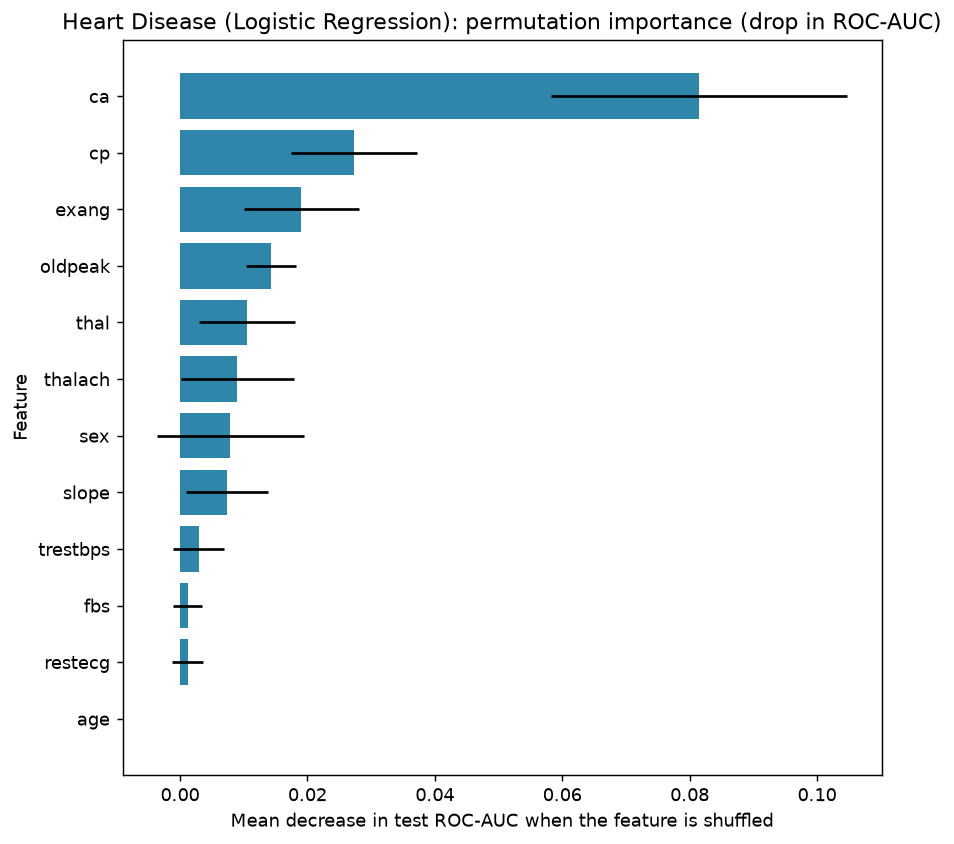

,feature,importance
0,thal_3.0,0.121
1,ca,0.108
2,thal_7.0,0.105
3,cp_4.0,0.101
4,thalach,0.098
5,oldpeak,0.074
6,age,0.061
7,chol,0.051


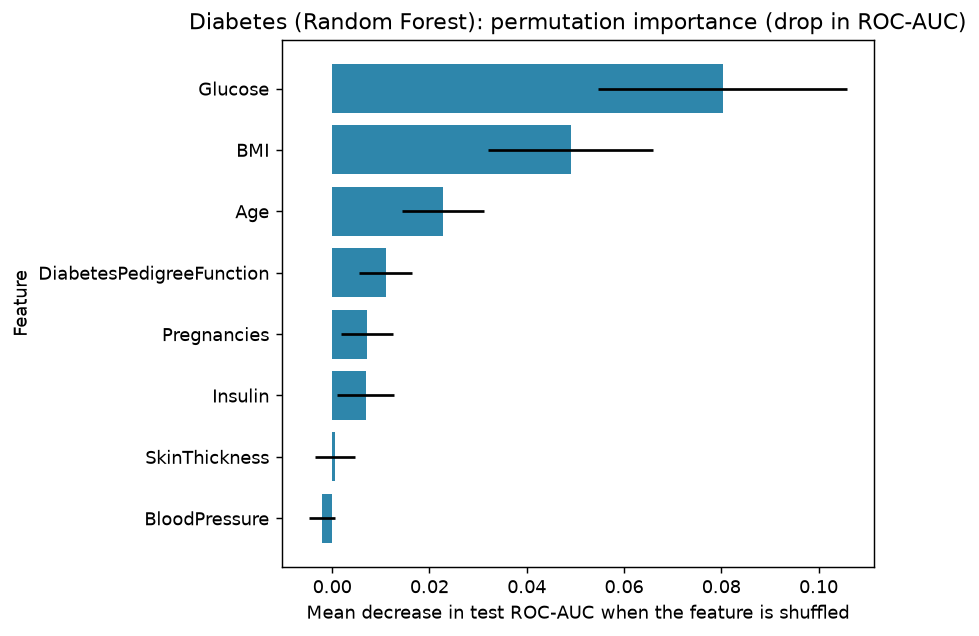

,feature,importance
0,Glucose,0.338
1,BMI,0.184
2,Age,0.120
3,Insulin,0.111
4,DiabetesPedigreeFunction,0.083
5,Pregnancies,0.059
6,SkinThickness,0.057
7,BloodPressure,0.047


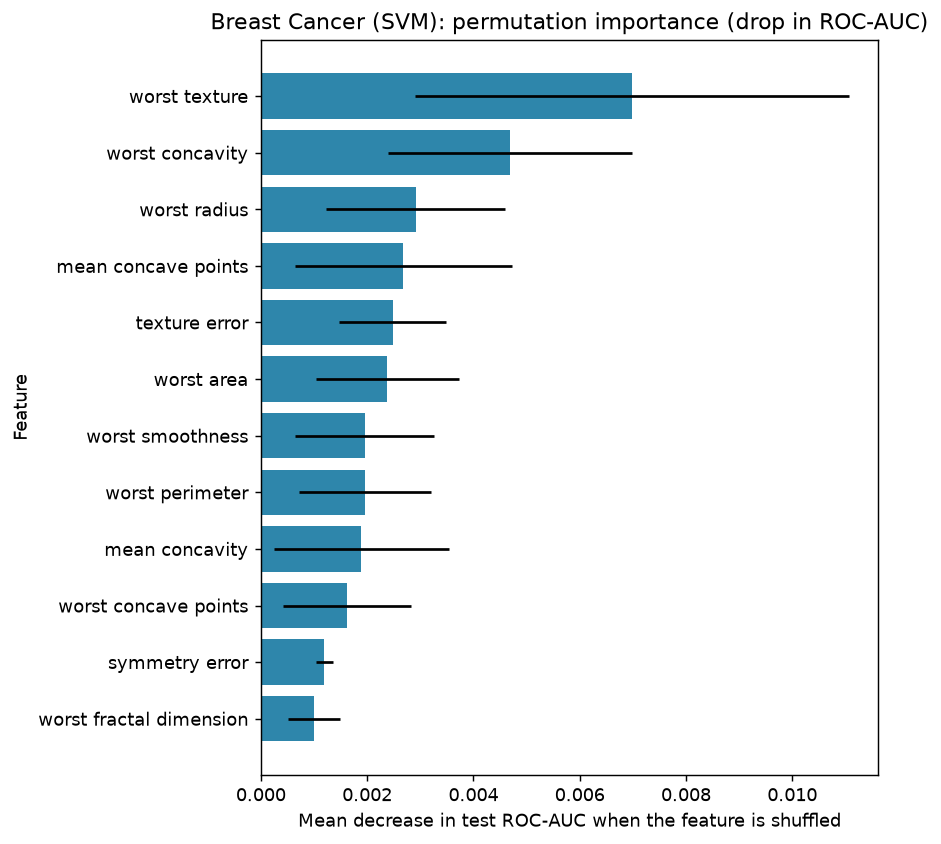

,feature,importance
0,worst perimeter,0.144
1,worst area,0.129
2,mean concave points,0.105
3,worst concave points,0.096
4,worst radius,0.078
5,mean concavity,0.069
6,mean radius,0.047
7,mean area,0.045


In [18]:
for key, res in results.items():
    display(Image(filename=str(FIGURES_DIR / f"{key}_feature_importance.png")))
    if "random_forest_importance" in res:
        display(pd.DataFrame(res["random_forest_importance"]).head(8).round(3))

## 20. Save models
The best pipeline (preprocessing + classifier) for each disease was saved to `models/` by `train_disease`. The check below reloads each saved model and predicts for the placeholder starting values from the app (not real patients) to confirm the save/load path works.

In [19]:
print("Saved files:", sorted(p.name for p in MODELS_DIR.glob("*.pkl")))
for key, cfg in DISEASES.items():
    starting_values = {f.name: f.default for f in cfg.features}
    print(cfg.title, "->", predict.predict_risk(key, starting_values))

Saved files: ['breast_cancer_model.pkl', 'diabetes_model.pkl', 'heart_model.pkl']
Heart Disease -> {'probability': 0.44177749121709786, 'label': 'Lower predicted risk', 'predicted_class': 0, 'threshold': 0.5, 'model_name': 'Logistic Regression', 'warnings': []}
Diabetes -> {'probability': 0.3049278325585067, 'label': 'Lower predicted risk', 'predicted_class': 0, 'threshold': 0.5, 'model_name': 'Random Forest', 'warnings': []}
Breast Cancer -> {'probability': 0.03078106452602579, 'label': 'Lower predicted risk', 'predicted_class': 0, 'threshold': 0.5, 'model_name': 'SVM', 'warnings': []}


## 21. Final conclusions

In [20]:
for key, res in results.items():
    m = res["tuned"][res["best_model"]]["metrics"]
    print(f"{DISEASES[key].title}: {res['best_model']} was selected. On the held-out test set it reached "
          f"accuracy {m['accuracy']:.3f}, recall {m['recall']:.3f}, precision {m['precision']:.3f}, "
          f"F1 {m['f1']:.3f}, ROC-AUC {m['roc_auc']:.3f}.")

Heart Disease: Logistic Regression was selected. On the held-out test set it reached accuracy 0.869, recall 0.929, precision 0.812, F1 0.867, ROC-AUC 0.961.
Diabetes: Random Forest was selected. On the held-out test set it reached accuracy 0.753, recall 0.778, precision 0.618, F1 0.689, ROC-AUC 0.822.
Breast Cancer: SVM was selected. On the held-out test set it reached accuracy 0.982, recall 0.952, precision 1.000, F1 0.976, ROC-AUC 0.997.


### Interpretation and limitations
* Results above are computed from a single stratified split of relatively small datasets (hundreds of records). With so few test cases a difference of one or two patients moves recall noticeably, so small gaps between models are not strong evidence.
* The Cleveland and Pima datasets come from specific populations and time periods; the models may not generalise to other groups.
* Feature importance describes what the model uses, not medical causation.
* The 0.5 probability threshold is a default; a screening setting might choose a lower threshold to favour recall.
* This is an educational demonstration. It is **not** a medical device and must not be used for diagnosis or treatment decisions.

To use the trained models interactively, run `streamlit run app.py` from the project root.